# Task 2 – Exploratory Data Analysis (EDA)
**Internship:** Auspify Technologies – Data Science Program  
**Intern:** Shabbir Moomin (Colombo, Sri Lanka)  
**Dataset:** `Netflix_Cleaned.csv` (output of Task 1)

**Workflow**
1. Analyze dataset structure and statistics
2. Study content distribution by type
3. Identify top countries and categories
4. Create visualizations for key metrics
5. Summarize findings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# one consistent look for all the charts (otherwise each one looks different, ugly)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

NETFLIX_RED = '#E50914'   # brand colour, because why not
GREY = '#564d4d'

# if the Task 1 output is missing, rerun the Task 1 notebook first
df = pd.read_csv('Netflix_Cleaned.csv', parse_dates=['date_added'])
print(df.shape)
df.head(3)

(8786, 34)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,...,genre_international_movies,genre_dramas,genre_comedies,genre_international_tv_shows,genre_documentaries,genre_action_and_adventure,genre_tv_dramas,genre_independent_movies,genre_children_and_family_movies,genre_romantic_movies
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,...,0,0,0,0,1,0,0,0,0,0
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",...,0,0,0,1,0,0,0,0,0,0
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",...,0,0,0,0,0,0,1,0,0,0


## Step 1 – Analyze dataset structure and statistics

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8786 entries, 0 to 8785
Data columns (total 34 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   show_id                           8786 non-null   str           
 1   type                              8786 non-null   str           
 2   title                             8786 non-null   str           
 3   director                          8786 non-null   str           
 4   country                           8786 non-null   str           
 5   date_added                        8786 non-null   datetime64[us]
 6   release_year                      8786 non-null   int64         
 7   rating                            8786 non-null   str           
 8   duration                          8786 non-null   str           
 9   listed_in                         8786 non-null   str           
 10  year_added                        8786 non-null   int64    

In [3]:
# numeric summary - release_year, year_added, duration etc.
df[['release_year', 'year_added', 'years_to_add', 'duration_min', 'seasons']].describe().round(1)

,release_year,year_added,years_to_add,duration_min,seasons
count,8786.0,8786.0,8786.0,6123.0,2663.0
mean,2014.2,2018.9,4.7,99.6,1.8
std,8.8,1.6,8.8,28.3,1.6
min,1925.0,2008.0,0.0,3.0,1.0
25%,2013.0,2018.0,0.0,87.0,1.0
50%,2017.0,2019.0,1.0,98.0,1.0
75%,2019.0,2020.0,5.0,114.0,2.0
max,2021.0,2021.0,93.0,312.0,17.0


In [4]:
# categorical summary
df[['type', 'primary_country', 'rating', 'audience', 'primary_genre']].describe()

,type,primary_country,rating,audience,primary_genre
count,8786,8786,8786,8786,8786
unique,2,86,14,5,36
top,Movie,United States,TV-MA,Adults,Dramas
freq,6123,3240,3204,4005,1597


In [5]:
# nulls: only duration_min / seasons should have them (movies have no seasons & vice versa) - that's expected
df.isnull().sum()[lambda s: s > 0]

duration_min    2663
seasons         6123
dtype: int64

In [6]:
# Unknown labels from Task 1 - worth knowing before we draw conclusions about directors / countries
print(f"Unknown director: {(df['director'] == 'Unknown').mean():.1%}")
print(f"Unknown country : {(df['country'] == 'Unknown').mean():.1%}")

Unknown director: 29.4%
Unknown country : 3.3%


## Step 2 – Study content distribution by type

type
Movie      6123
TV Show    2663
Name: count, dtype: int64 

type
Movie      0.697
TV Show    0.303
Name: count, dtype: float64


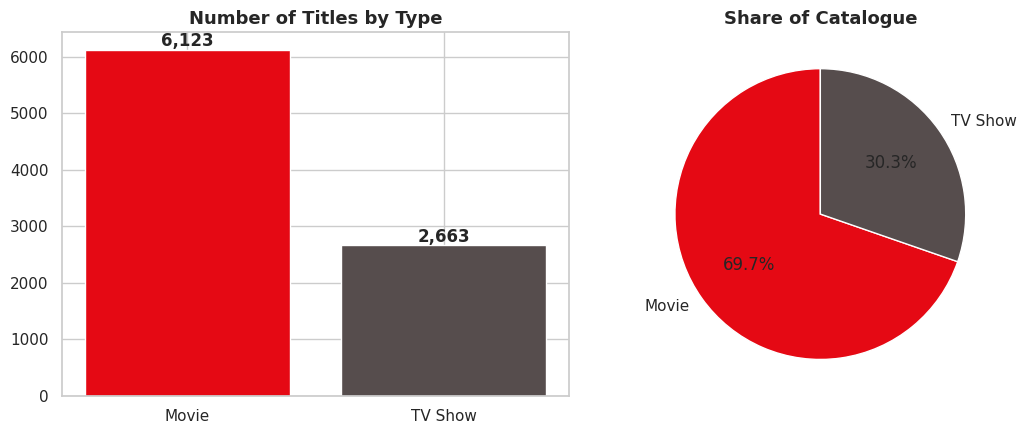

In [7]:
type_counts = df['type'].value_counts()
print(type_counts, '\n')
print((type_counts / len(df)).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].bar(type_counts.index, type_counts.values, color=[NETFLIX_RED, GREY])
ax[0].set_title('Number of Titles by Type')
for i, v in enumerate(type_counts.values):
    ax[0].text(i, v + 60, f'{v:,}', ha='center', fontweight='bold')
ax[1].pie(type_counts.values, labels=type_counts.index, autopct='%1.1f%%',
          colors=[NETFLIX_RED, GREY], startangle=90, wedgeprops={'edgecolor': 'white'})
ax[1].set_title('Share of Catalogue')
plt.tight_layout(); plt.show()

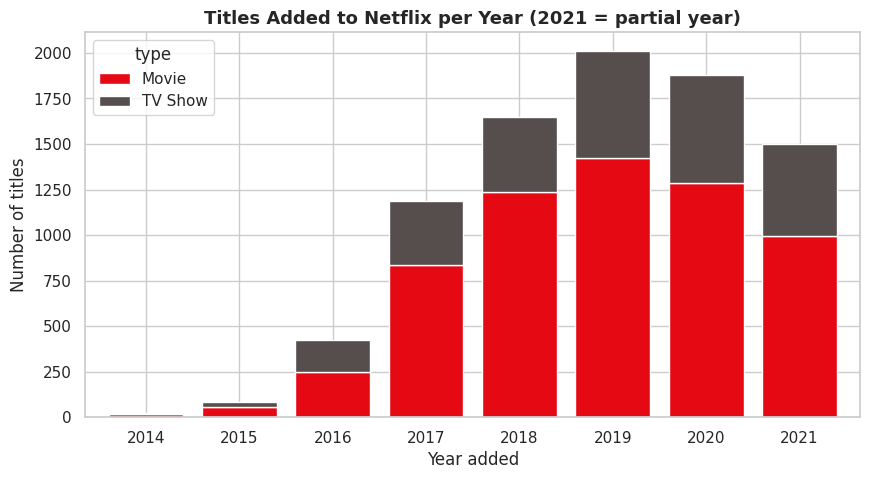

In [8]:
# how has the catalogue grown over time, split by type?
# NOTE: 2021 only goes up to 25 Sep in this data -> it's a partial year, don't read the drop as a real decline!
yearly = df[df['year_added'] >= 2014].groupby(['year_added', 'type']).size().unstack(fill_value=0)

ax = yearly.plot(kind='bar', stacked=True, color=[NETFLIX_RED, GREY], width=0.8)
ax.set_title('Titles Added to Netflix per Year (2021 = partial year)')
ax.set_xlabel('Year added'); ax.set_ylabel('Number of titles')
plt.xticks(rotation=0); plt.show()

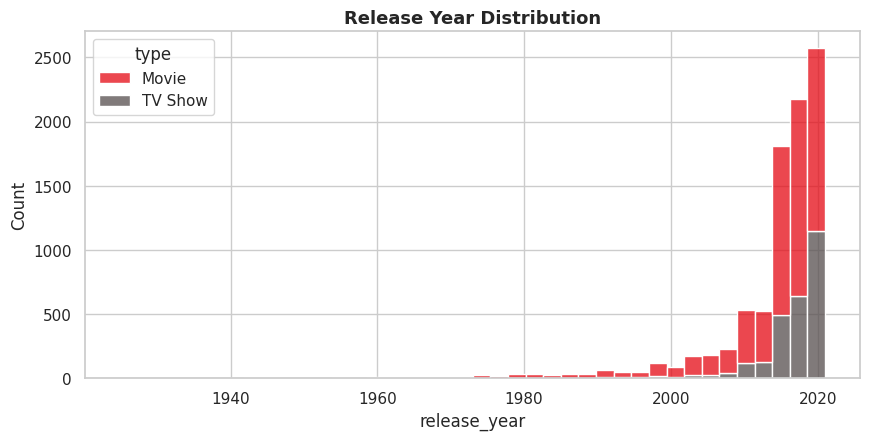

Titles released 2015 or later: 70.6%


In [9]:
# release year distribution - mostly recent stuff?
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(data=df, x='release_year', hue='type', multiple='stack', bins=40,
             palette=[NETFLIX_RED, GREY], ax=ax)
ax.set_title('Release Year Distribution')
plt.show()
print(f"Titles released 2015 or later: {(df['release_year'] >= 2015).mean():.1%}")

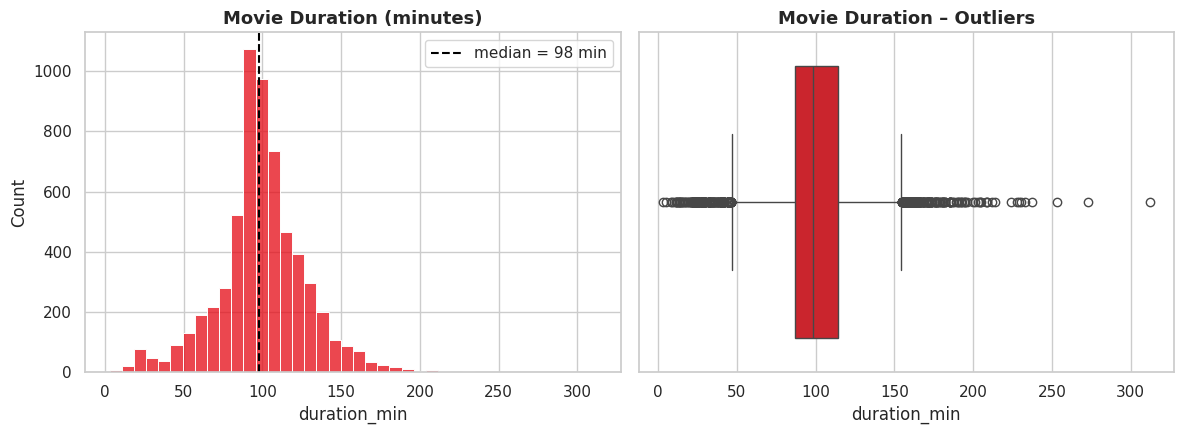

,title,duration_min
2819,Silent,3.0
2175,Sol Levante,5.0
1344,Cops and Robbers,8.0


,title,duration_min
7818,Black Mirror: Bandersnatch,312.0
151,Headspace: Unwind Your Mind,273.0
2019,The School of Mischief,253.0


In [10]:
# movie length - histogram + boxplot to spot outliers
movies = df[df['type'] == 'Movie']

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(movies['duration_min'], bins=40, color=NETFLIX_RED, ax=ax[0])
ax[0].axvline(movies['duration_min'].median(), color='black', ls='--', label=f"median = {movies['duration_min'].median():.0f} min")
ax[0].set_title('Movie Duration (minutes)'); ax[0].legend()
sns.boxplot(x=movies['duration_min'], color=NETFLIX_RED, ax=ax[1])
ax[1].set_title('Movie Duration – Outliers')
plt.tight_layout(); plt.show()

# the extreme ends (very short / very long) - probably shorts, specials, or stand-up
display(movies.nsmallest(3, 'duration_min')[['title', 'duration_min']])
display(movies.nlargest(3, 'duration_min')[['title', 'duration_min']])

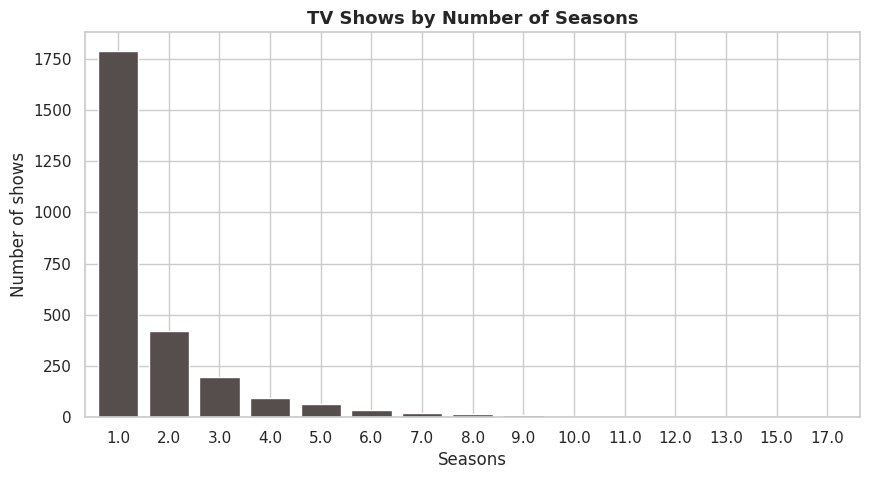

TV shows with just 1 season: 67.2%


In [11]:
# TV shows: most are 1 season only (Netflix cancels fast, lol)
season_counts = df['seasons'].value_counts().sort_index()
ax = season_counts.plot(kind='bar', color=GREY, width=0.8)
ax.set_title('TV Shows by Number of Seasons')
ax.set_xlabel('Seasons'); ax.set_ylabel('Number of shows')
plt.xticks(rotation=0); plt.show()
print(f"TV shows with just 1 season: {(df['seasons'] == 1).sum() / df['seasons'].notna().sum():.1%}")

## Step 3 – Identify top countries and categories

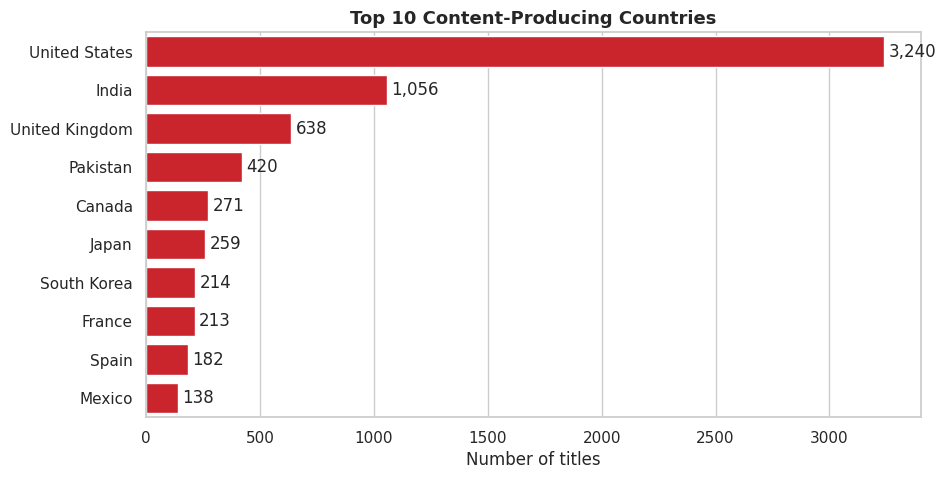

Top 3 countries make up 58.1% of titles with a known country


In [12]:
# top 10 countries (primary/first-listed country, 'Unknown' excluded)
known = df[df['primary_country'] != 'Unknown']
top_countries = known['primary_country'].value_counts().head(10)

ax = sns.barplot(x=top_countries.values, y=top_countries.index, color=NETFLIX_RED)
ax.set_title('Top 10 Content-Producing Countries')
ax.set_xlabel('Number of titles'); ax.set_ylabel('')
for i, v in enumerate(top_countries.values):
    ax.text(v + 20, i, f'{v:,}', va='center')
plt.show()
print(f'Top 3 countries make up {top_countries.head(3).sum() / len(known):.1%} of titles with a known country')

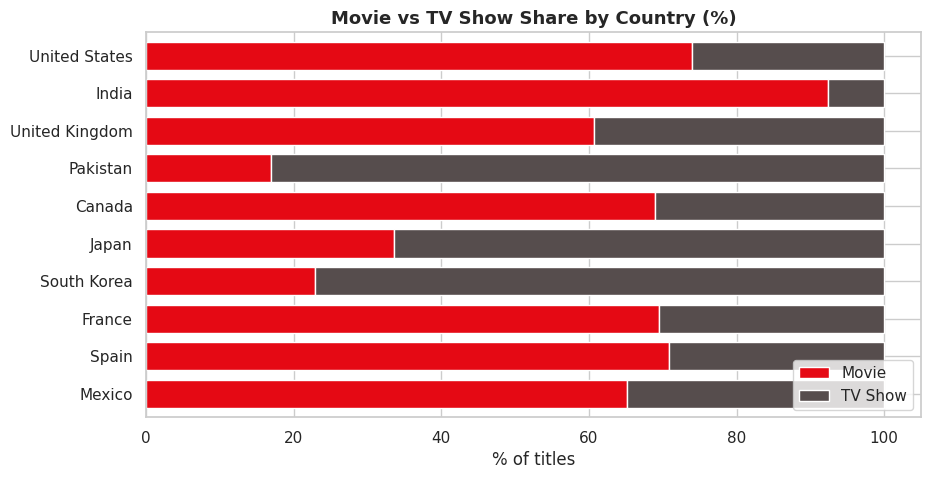

In [13]:
# movies vs TV mix for the top 10 countries
# (e.g. does South Korea lean towards TV shows? does Pakistan/India lean towards movies?)
mix = (pd.crosstab(known['primary_country'], known['type'], normalize='index')
         .loc[top_countries.index] * 100)
ax = mix.plot(kind='barh', stacked=True, color=[NETFLIX_RED, GREY], width=0.75)
ax.invert_yaxis()
ax.set_title('Movie vs TV Show Share by Country (%)'); ax.set_xlabel('% of titles'); ax.set_ylabel('')
ax.legend(loc='lower right')
plt.show()

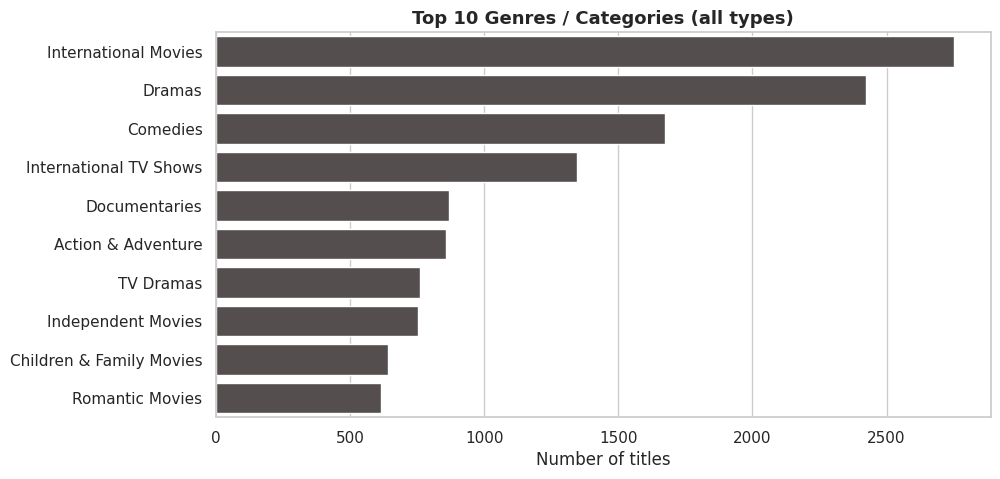

In [14]:
# top genres: a title has several genres, so count each one (explode the list)
genres = df['listed_in'].str.split(',').explode().str.strip()
top_genres = genres.value_counts().head(10)

ax = sns.barplot(x=top_genres.values, y=top_genres.index, color=GREY)
ax.set_title('Top 10 Genres / Categories (all types)')
ax.set_xlabel('Number of titles'); ax.set_ylabel('')
plt.show()

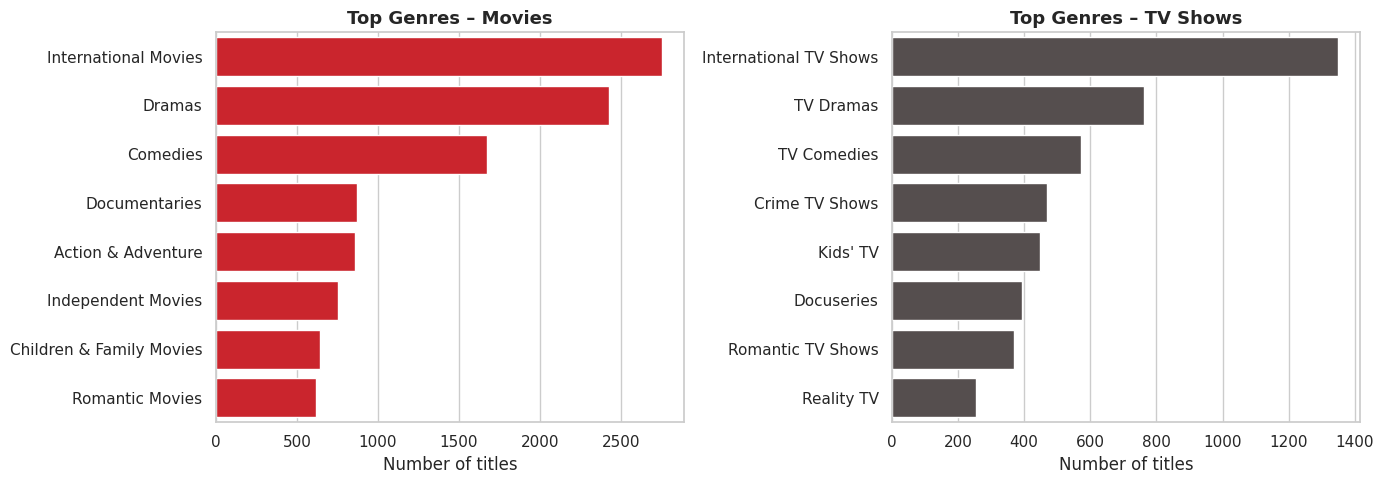

In [15]:
# genres separately for Movies and TV Shows (the combined chart hides the difference)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (t, colr) in zip(ax, [('Movie', NETFLIX_RED), ('TV Show', GREY)]):
    g = df[df['type'] == t]['listed_in'].str.split(',').explode().str.strip().value_counts().head(8)
    sns.barplot(x=g.values, y=g.index, color=colr, ax=a)
    a.set_title(f'Top Genres – {t}s'); a.set_xlabel('Number of titles'); a.set_ylabel('')
plt.tight_layout(); plt.show()

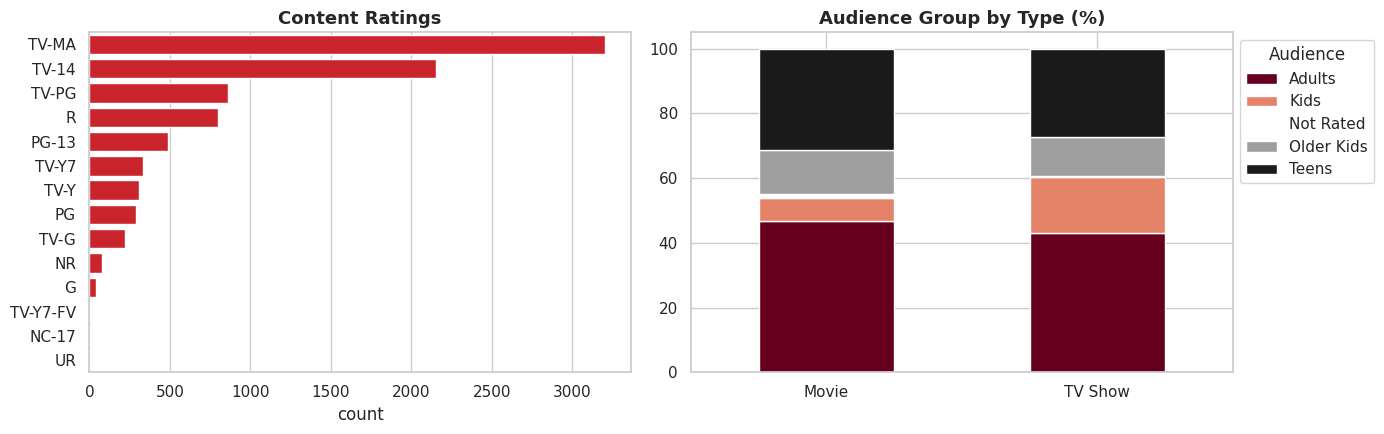

In [16]:
# ratings + audience groups
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

order = df['rating'].value_counts().index
sns.countplot(data=df, y='rating', order=order, color=NETFLIX_RED, ax=ax[0])
ax[0].set_title('Content Ratings'); ax[0].set_ylabel('')

aud = pd.crosstab(df['type'], df['audience'], normalize='index') * 100
aud.plot(kind='bar', stacked=True, ax=ax[1], colormap='RdGy', rot=0)
ax[1].set_title('Audience Group by Type (%)'); ax[1].set_xlabel(''); ax[1].legend(title='Audience', bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

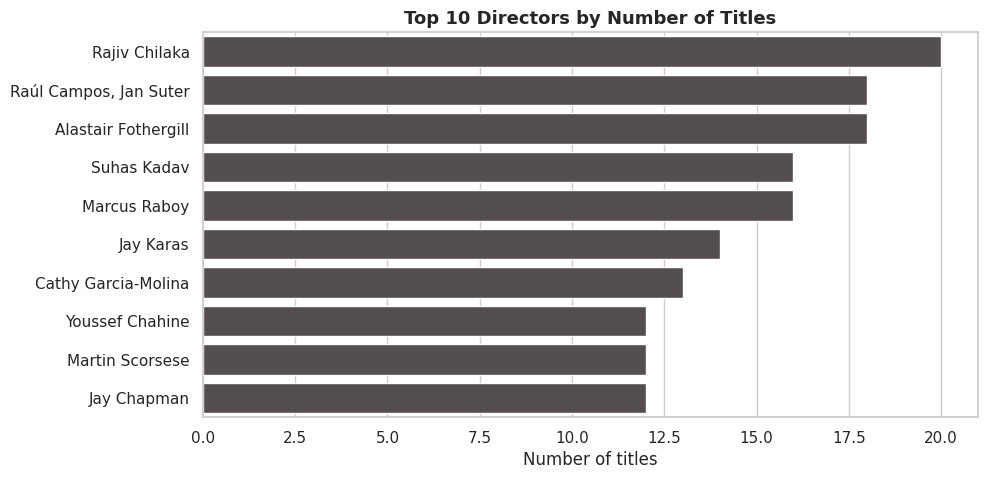

In [17]:
# most frequent directors (excluding Unknown) - mostly kids' content and stand-up specials? let's see
top_dir = df[df['director'] != 'Unknown']['director'].value_counts().head(10)
ax = sns.barplot(x=top_dir.values, y=top_dir.index, color=GREY)
ax.set_title('Top 10 Directors by Number of Titles'); ax.set_xlabel('Number of titles'); ax.set_ylabel('')
plt.show()

## Step 4 – Create visualizations for key metrics (timing & relationships)

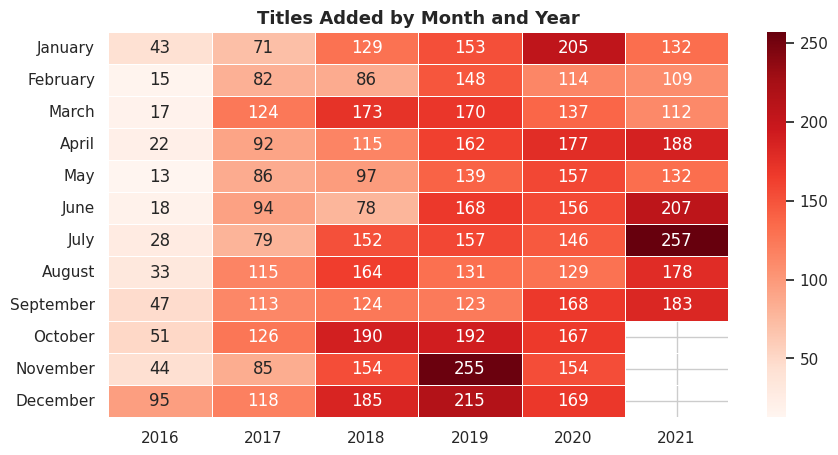

In [18]:
# when does Netflix add content? month x year heatmap (2016 onwards, 2021 partial)
heat = (df[df['year_added'] >= 2016]
        .pivot_table(index='month_name', columns='year_added', values='show_id', aggfunc='count')
        .reindex(['January','February','March','April','May','June','July',
                  'August','September','October','November','December']))
sns.heatmap(heat, annot=True, fmt='.0f', cmap='Reds', linewidths=.5)
plt.title('Titles Added by Month and Year'); plt.xlabel(''); plt.ylabel('')
plt.show()

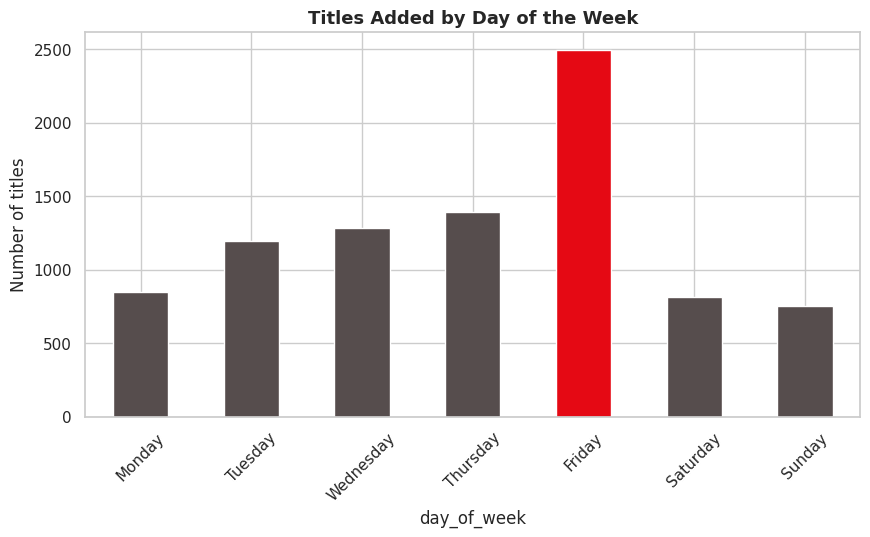

In [19]:
# day of the week
dow = df['day_of_week'].value_counts().reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
ax = dow.plot(kind='bar', color=[GREY]*4 + [NETFLIX_RED] + [GREY]*2, rot=45)
ax.set_title('Titles Added by Day of the Week'); ax.set_ylabel('Number of titles')
plt.show()

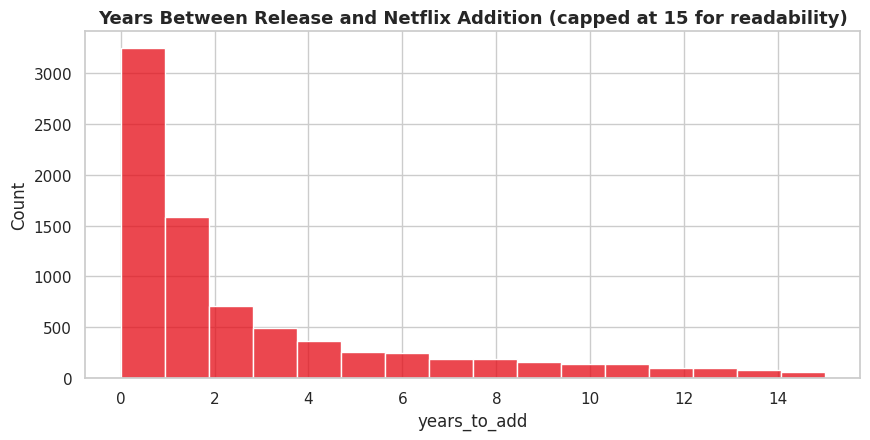

Added within 1 year of release: 55.0%
Median gap (years): 1.0


In [20]:
# how fast does Netflix add a title after its release?
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(df[df['years_to_add'] <= 15]['years_to_add'], bins=16, color=NETFLIX_RED, ax=ax)
ax.set_title('Years Between Release and Netflix Addition (capped at 15 for readability)')
plt.show()
print(f"Added within 1 year of release: {(df['years_to_add'] <= 1).mean():.1%}")
print('Median gap (years):', df['years_to_add'].median())

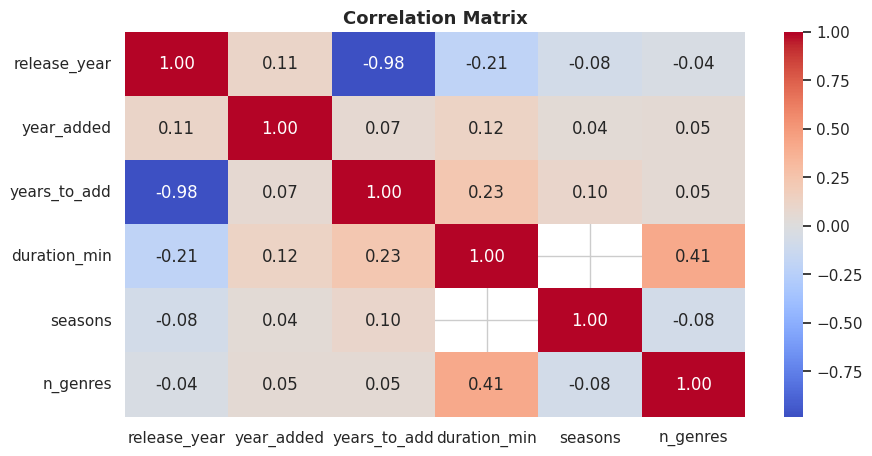

In [21]:
# quick correlation check among the numeric columns (not much expected, but we check anyway)
num = df[['release_year', 'year_added', 'years_to_add', 'duration_min', 'seasons', 'n_genres']]
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix'); plt.show()

## Step 5 – Summary of findings

**Content mix**
- Netflix's catalogue here is **~70% Movies (6,123) and ~30% TV Shows (2,663)**.
- Most TV shows are short-lived: **about two thirds (~67%) have only 1 season**.
- Movies run a median of **98 minutes** (mean ≈ 100); there are very short titles (a few minutes) and a handful of 200+ minute outliers.

**Growth & timing**
- Additions grew sharply from 2016 and **peaked in 2019 (2,013 titles)**. 2020 was close behind; 2021 looks lower only because the data stops on 25 Sep 2021.
- About **70% of titles were released in 2015 or later**, so the catalogue is dominated by recent content.
- More than half of titles (~55%) were added within a year of release.
- **Friday is by far the most common day for additions** (≈2,500 titles, almost 2× any other day). July and December are the busiest months.

**Countries**
- The **United States leads (3,240)**, followed by **India (~1,056)** and the **United Kingdom (638)**; Pakistan, Canada, Japan, South Korea, France, Spain and Mexico complete the top 10.
- The top 3 countries alone account for about **58% of all titles with a known country**.

**Genres & audience**
- **International Movies (2,751)**, **Dramas (2,423)** and **Comedies (1,673)** are the biggest categories overall; for TV, **International TV Shows**, **TV Dramas** and **TV Comedies** lead.
- **Adults (TV-MA / R) is the largest audience group (~46%)**, followed by Teens (TV-14 / PG-13, ~30%). TV shows skew more towards kids' content (≈17%) than movies (≈7%).
- The most frequent directors are mostly associated with children's animation, nature documentaries and stand-up specials (e.g. Rajiv Chilaka, Alastair Fothergill, Marcus Raboy).

**Caveats**
- Every `country` value in this file is a single country (no co-productions listed), so `primary_country` equals `country`, and the `n_countries` column from Task 1 is just 0/1 (Unknown vs known) – not useful for analysis.
- ~29% of directors and ~3% of countries are *Unknown*, so director / country rankings are based on the known subset only.
- The dataset is a sample (8,786 titles), so absolute numbers shouldn't be read as Netflix's full catalogue.

